In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Fix the path: go up one level from notebooks/ to the project root
PROJECT_ROOT = Path.cwd().parent

# 2. Use the PROJECT_ROOT to read the file
df = pd.read_parquet(PROJECT_ROOT / "data/processed/listings_clean.parquet")
print(f"Shape: {df.shape}")

# Look at the 6 candidate clustering features
CLUSTER_FEATURES = [
    "price",
    "accommodates",
    "bedrooms",
    "amenity_count",
    "distance_to_center_km",
]
print(df[CLUSTER_FEATURES].describe())
print("\nMissing values:")
print(df[CLUSTER_FEATURES].isna().sum())

Shape: (16558, 94)
              price  accommodates      bedrooms  amenity_count  \
count       16558.0  16558.000000  16553.000000   16558.000000   
mean    6321.835393      3.726597      1.456715      33.415388   
std    10311.441511      2.260171      1.160960      15.283848   
min           320.0      1.000000      0.000000       0.000000   
25%          3000.0      2.000000      1.000000      23.000000   
50%         4469.75      3.000000      1.000000      34.000000   
75%       6856.5675      4.000000      2.000000      44.000000   
max       502353.28     16.000000     50.000000      97.000000   

       distance_to_center_km  
count           16558.000000  
mean                7.527482  
std                10.705575  
min                 0.040618  
25%                 2.653694  
50%                 3.758304  
75%                 6.662455  
max                81.188220  

Missing values:
price                    0
accommodates             0
bedrooms                 5
amenity_c

In [11]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Cast nullable dtypes to plain numpy floats
X = df[CLUSTER_FEATURES].astype("float64")

K_RANGE = range(2, 9)
inertias = []
silhouettes = []

for k in K_RANGE:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, random_state=42, n_init=10)),
    ])
    labels = pipe.fit_predict(X)
    inertias.append(pipe.named_steps["kmeans"].inertia_)

    # Transform X through the pipeline (imputed + scaled) for silhouette
    X_transformed = pipe[:-1].transform(X)   # everything except KMeans
    silhouettes.append(silhouette_score(X_transformed, labels))

    print(f"K={k}  inertia={inertias[-1]:,.0f}  silhouette={silhouettes[-1]:.3f}")

K=2  inertia=64,184  silhouette=0.394
K=3  inertia=54,451  silhouette=0.405
K=4  inertia=45,937  silhouette=0.400
K=5  inertia=37,868  silhouette=0.285
K=6  inertia=33,001  silhouette=0.286
K=7  inertia=30,042  silhouette=0.295
K=8  inertia=27,103  silhouette=0.297


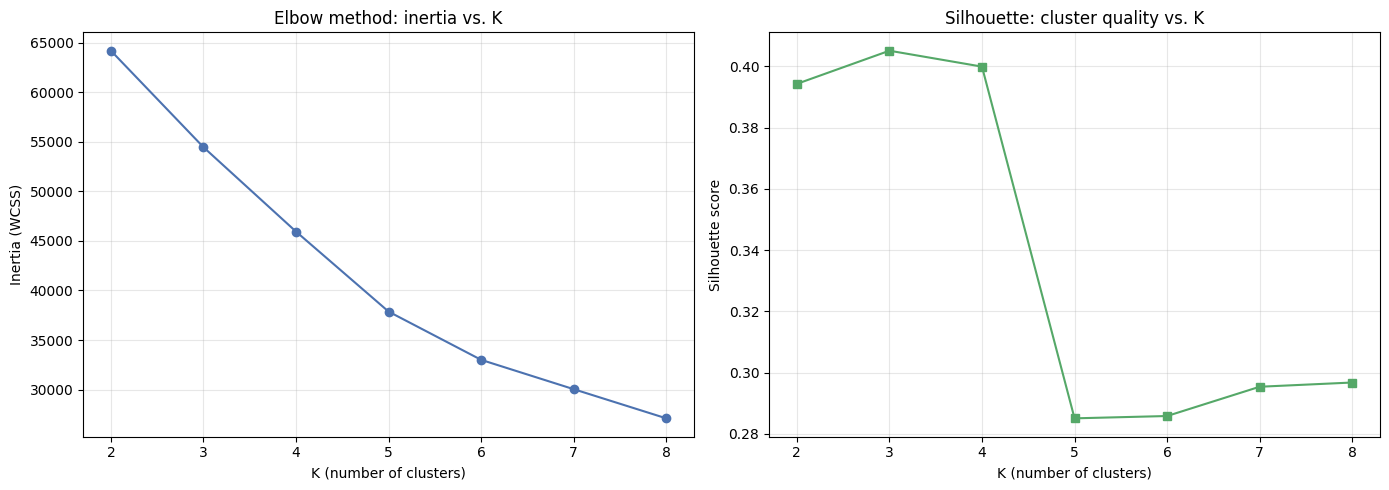

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_RANGE), inertias, "o-", color="#4C72B0")
axes[0].set_xlabel("K (number of clusters)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow method: inertia vs. K")
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_RANGE), silhouettes, "s-", color="#55A868")
axes[1].set_xlabel("K (number of clusters)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: cluster quality vs. K")
axes[1].grid(alpha=0.3)

fig.tight_layout()
Path("reports/clusters").mkdir(parents=True, exist_ok=True)
fig.savefig("reports/clusters/elbow_silhouette.png", dpi=160, bbox_inches="tight")
plt.show()

### K selection evidence

| K | inertia | silhouette |
|---|---|---|
| 2 | 64,184 | 0.394 |
| 3 | 54,451 | **0.405** |
| 4 | 45,937 | 0.400 |
| 5 | 37,868 | 0.285 |
| 6 | 33,001 | 0.286 |
| 7 | 30,042 | 0.295 |
| 8 | 27,103 | 0.297 |

**Elbow:** inertia drops sharply until K=4 (64k → 54k → 46k), then flattens (the drop from K=4 to K=5 is noticeably smaller).

**Silhouette:** peaks at K=3 (0.405), drops off after (stays high at K=4, then collapses to 0.285 at K=5).

**Decision:** I will use K=3, because the silhouette score is highest here and K=3 sits in the steep part of the elbow curve. K=4 is a close second, but the sharp drop at K=5 confirms that the algorithm starts slicing existing clusters into noise rather than discovering new structure. (Note: `bathrooms` was removed from the feature list as it contained 100% missing values, leaving 5 final clustering features.)